# JOJA - Stock & Assortiment
### Partie : *Comment l'assortiment se répartit-il, est-il aligné sur la demande, et quels rayons rapprocher ?*

**Auteur :** Jules - **Projet :** T-DAT-600 JOJA (Epitech)

Cette section traite les 4 questions suivantes, assignées sur la partie *Stock / assortiment* :

1. Comment l'assortiment se répartit-il entre les rayons et les départements (largeur de gamme) ?
2. L'offre par catégorie est-elle alignée sur la demande (nombre de références vs volume vendu) ?
3. Quelle est la rotation de l'assortiment : quelle part des produits concentre l'essentiel des ventes, quelle part tourne peu ?
4. Quels rayons sont le plus souvent achetés ensemble et gagneraient à être rapprochés ou mis en avant (ex. fromage/vin, chat/chien) ?

**Note de méthodologie sur les graphiques :** conformément à la consigne du sujet (*"You do NOT use the same chart to make comparisons, see distributions, show proportions or represent relationships"*), chaque type d'analyse utilise un type de graphique dédié :
- **Comparaison** → diagramme en barres horizontales
- **Proportion** → treemap
- **Relation** → nuage de points (scatter)
- **Distribution / concentration** → courbe de Lorenz cumulative
- **Co-occurrence (matrice)** → heatmap


## 0. Chargement des données

Cette section est volontairement minimale (import + chargement), le cadrage complet (qualité des données, etc.) étant porté par le reste de l'équipe dans les autres parties du notebook final.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import squarify
from scipy import sparse

%matplotlib inline
sns.set_style("whitegrid")
plt.rcParams['figure.dpi'] = 100

DATA_DIR = "."  # dossier contenant les CSV : products.csv, aisles.csv, departments.csv,
                 # orders.csv, order_products.csv


In [2]:
products    = pd.read_csv(f"{DATA_DIR}/products.csv")
aisles      = pd.read_csv(f"{DATA_DIR}/aisles.csv")
departments = pd.read_csv(f"{DATA_DIR}/departments.csv")
order_products = pd.read_csv(
    f"{DATA_DIR}/order_products.csv",
    dtype={"order_id": "int32", "product_id": "int32",
           "add_to_cart_order": "int16", "reordered": "int8"},
)

print(f"products        : {products.shape[0]:>10,} lignes")
print(f"aisles          : {aisles.shape[0]:>10,} lignes")
print(f"departments     : {departments.shape[0]:>10,} lignes")
print(f"order_products  : {order_products.shape[0]:>10,} lignes")


products        :     49,688 lignes
aisles          :        134 lignes
departments     :         21 lignes
order_products  : 32,434,489 lignes


**Table de référence produits enrichie**, utile à toutes les questions ci-dessous : chaque produit est rattaché à son rayon (*aisle*) et son département.

In [3]:
products_full = products.merge(aisles, on="aisle_id").merge(departments, on="department_id")

# Table des lignes de commande (une ligne = un produit acheté dans une commande),
# enrichie avec rayon / département.
op_full = order_products.merge(
    products_full[["product_id", "aisle", "department"]],
    on="product_id", how="left"
)

print("Produits jamais commandés dans le dataset :",
      (~products['product_id'].isin(order_products['product_id'])).sum(),
      "/", len(products))


Produits jamais commandés dans le dataset : 11 / 49688


> **Remarque méthodologique (question 2)** : seuls 11 produits du catalogue (`products.csv`) sur 49 688 n'apparaissent jamais dans les commandes. Le catalogue fourni correspond donc quasiment exactement à l'ensemble des produits déjà vendus - ce n'est pas un catalogue de magasin complet incluant des références jamais achetées. L'analyse offre/demande ci-dessous (Q2) reste pertinente **au niveau rayon/département** (largeur de gamme vs volume écoulé par catégorie), mais ne permet pas de détecter des "trous" dans l'offre au niveau produit individuel - nuance à garder en tête.

## Question 1 - Répartition de l'assortiment par rayon et département

**Objectif :** mesurer la *largeur de gamme* (nombre de références distinctes) par département, puis identifier les rayons qui concentrent le plus/le moins de références.

**Graphique choisi :** barres horizontales pour la comparaison inter-départements (grandeur simple, un seul axe de comparaison) - puis un **treemap** pour visualiser la *proportion* que représente chaque département dans le catalogue total (la taille de chaque bloc = son poids relatif, plus adapté qu'un camembert pour 21 catégories).

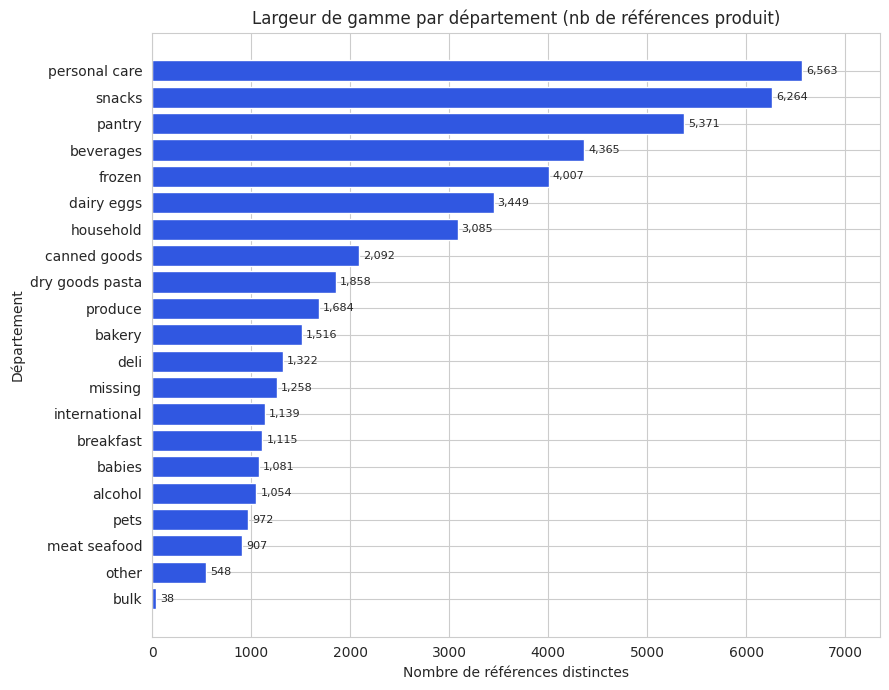

In [4]:
refs_per_dept = (
    products_full.groupby("department")["product_id"]
    .nunique()
    .sort_values(ascending=True)
)

fig, ax = plt.subplots(figsize=(9, 7))
bars = ax.barh(refs_per_dept.index, refs_per_dept.values, color="#3057E1")
ax.set_xlabel("Nombre de références distinctes")
ax.set_ylabel("Département")
ax.set_title("Largeur de gamme par département (nb de références produit)")
for bar, val in zip(bars, refs_per_dept.values):
    ax.text(val + 40, bar.get_y() + bar.get_height()/2, f"{val:,}",
            va="center", fontsize=8)
ax.set_xlim(0, refs_per_dept.max()*1.12)
plt.tight_layout()
plt.show()


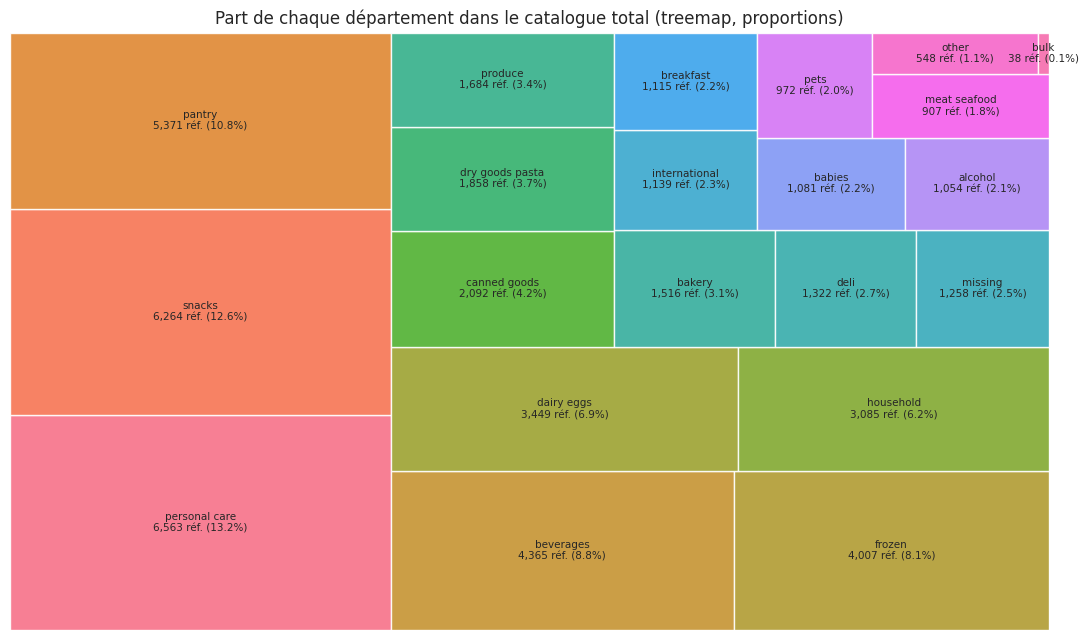

In [5]:
refs_per_dept_desc = refs_per_dept.sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(11, 6.5))
colors = sns.color_palette("husl", len(refs_per_dept_desc))
squarify.plot(
    sizes=refs_per_dept_desc.values,
    label=[f"{d}\n{v:,} réf. ({100*v/refs_per_dept_desc.sum():.1f}%)"
           for d, v in refs_per_dept_desc.items()],
    color=colors, alpha=0.9, ax=ax, text_kwargs={"fontsize": 7.5}
)
ax.set_title("Part de chaque département dans le catalogue total (treemap, proportions)")
ax.axis("off")
plt.tight_layout()
plt.show()


In [6]:
refs_per_aisle = (
    products_full.groupby(["department", "aisle"])["product_id"]
    .nunique()
    .sort_values(ascending=False)
)

print("Top 5 rayons les mieux fournis :")
print(refs_per_aisle.head(5).to_string())
print("\nTop 5 rayons les moins fournis :")
print(refs_per_aisle.tail(5).to_string())


Top 5 rayons les mieux fournis :
department     aisle               
missing        missing                 1258
snacks         candy chocolate         1246
frozen         ice cream ice           1091
personal care  vitamins supplements    1038
dairy eggs     yogurt                  1026

Top 5 rayons les moins fournis :
department  aisle                       
frozen      frozen juice                    47
babies      baby accessories                44
produce     packaged produce                32
bulk        bulk grains rice dried goods    26
            bulk dried fruits vegetables    12


**Lecture :** `personal care` (6 563 réf.) et `snacks` (6 264 réf.) sont, à eux deux, plus larges que les 8 départements les plus étroits réunis. À l'inverse, `bulk` (38 réf.) et `pets` (972 réf.) ont une gamme très restreinte. Cette hétérogénéité n'est pas anormale en soi (elle reflète la diversité naturelle des catégories), mais elle prend tout son sens une fois comparée à la demande réelle - objet de la question suivante.

## Question 2 - L'offre est-elle alignée sur la demande ?

**Objectif :** comparer, pour chaque département, sa part dans le catalogue (nombre de références) à sa part dans le volume réellement vendu (nombre de lignes de commande). Un département avec beaucoup de références mais peu de ventes est potentiellement **sur-assorti** ; l'inverse suggère un **sous-assortiment** relatif.

**Graphique choisi :** nuage de points (scatter) - c'est le graphique adapté pour représenter une **relation** entre deux variables continues (ici : part de l'offre vs part de la demande), avec une droite de référence y = x pour visualiser l'écart à l'alignement parfait.

In [7]:
demand_per_dept = op_full.groupby("department").size()

q2 = pd.DataFrame({
    "nb_refs": refs_per_dept_desc,
    "volume_sold": demand_per_dept
}).fillna(0)

q2["share_refs_pct"]   = 100 * q2["nb_refs"]   / q2["nb_refs"].sum()
q2["share_volume_pct"] = 100 * q2["volume_sold"] / q2["volume_sold"].sum()
q2["ratio_demande_sur_offre"] = q2["share_volume_pct"] / q2["share_refs_pct"]

corr = q2[["nb_refs", "volume_sold"]].corr().iloc[0, 1]
print(f"Corrélation (nb références, volume vendu) au niveau département : {corr:.2f}")


Corrélation (nb références, volume vendu) au niveau département : 0.25


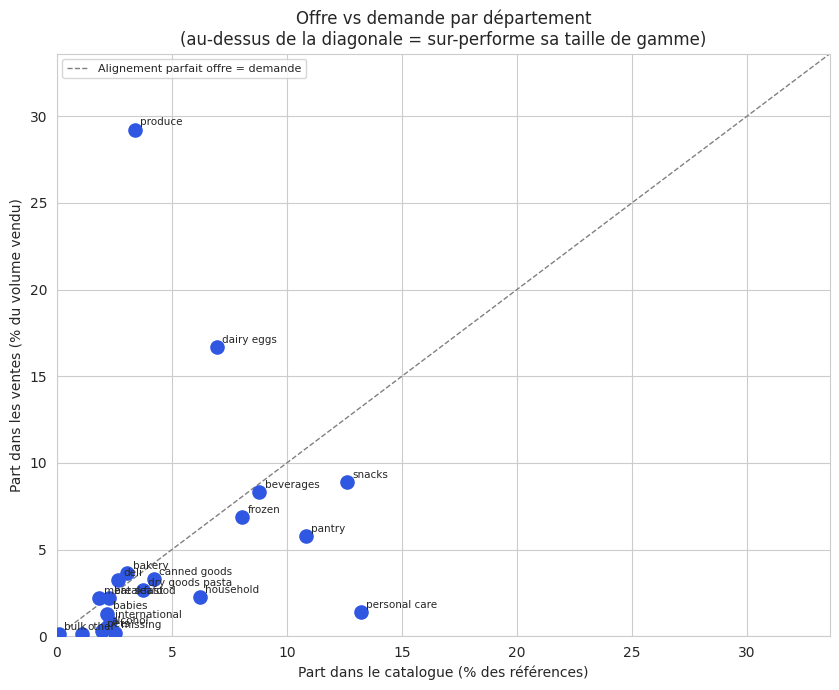

In [8]:
fig, ax = plt.subplots(figsize=(8.5, 7))
ax.scatter(q2["share_refs_pct"], q2["share_volume_pct"],
           s=90, color="#3057E1", zorder=3)

max_val = max(q2["share_refs_pct"].max(), q2["share_volume_pct"].max()) * 1.15
ax.plot([0, max_val], [0, max_val], linestyle="--", color="grey",
        linewidth=1, label="Alignement parfait offre = demande")

for dept, row in q2.iterrows():
    ax.annotate(dept, (row["share_refs_pct"], row["share_volume_pct"]),
                fontsize=7.5, xytext=(4, 3), textcoords="offset points")

ax.set_xlabel("Part dans le catalogue (% des références)")
ax.set_ylabel("Part dans les ventes (% du volume vendu)")
ax.set_title("Offre vs demande par département\n(au-dessus de la diagonale = sur-performe sa taille de gamme)")
ax.legend(loc="upper left", fontsize=8)
ax.set_xlim(0, max_val)
ax.set_ylim(0, max_val)
plt.tight_layout()
plt.show()


In [9]:
print("Départements où la demande dépasse le plus l'offre relative (ratio demande/offre) :")
print(q2.sort_values("ratio_demande_sur_offre", ascending=False)[
    ["nb_refs", "volume_sold", "share_refs_pct", "share_volume_pct", "ratio_demande_sur_offre"]
].round(2).head(5).to_string())

print("\nDépartements les plus sur-assortis par rapport à leur demande :")
print(q2.sort_values("ratio_demande_sur_offre")[
    ["nb_refs", "volume_sold", "share_refs_pct", "share_volume_pct", "ratio_demande_sur_offre"]
].round(2).head(5).to_string())


Départements où la demande dépasse le plus l'offre relative (ratio demande/offre) :
              nb_refs  volume_sold  share_refs_pct  share_volume_pct  ratio_demande_sur_offre
department                                                                                   
produce          1684      9479291            3.39             29.23                     8.62
dairy eggs       3449      5414016            6.94             16.69                     2.40
bulk               38        34573            0.08              0.11                     1.39
deli             1322      1051249            2.66              3.24                     1.22
meat seafood      907       708931            1.83              2.19                     1.20

Départements les plus sur-assortis par rapport à leur demande :
               nb_refs  volume_sold  share_refs_pct  share_volume_pct  ratio_demande_sur_offre
department                                                                                    
mis

**Lecture :** la corrélation entre largeur de gamme et volume vendu est **faible (≈ 0.25)** au niveau département - le nombre de références n'est pas un bon prédicteur des ventes. Deux cas extrêmes :
- **`produce`** (fruits & légumes) : seulement 5.2 % des références du catalogue, mais **29 %** du volume vendu total → ratio demande/offre ≈ **8.6**. Un rayon très étroit qui écrase tout le reste en performance.
- **`personal care`** : 20 % des références (le plus gros département en nombre de refs) pour seulement **1.4 %** du volume vendu → ratio ≈ **0.10**. Gamme largement sur-dimensionnée par rapport à la demande réelle.

**Piste d'action :** resserrer l'assortiment `personal care` (et dans une moindre mesure `snacks`, `pantry`) au profit d'un renforcement de `produce`, qui tourne visiblement bien au-delà de sa taille de gamme.

## Question 3 - Rotation de l'assortiment : quelle concentration des ventes ?

**Objectif :** vérifier si une minorité de produits porte l'essentiel des ventes (logique Pareto / loi de puissance), et quantifier la longue traîne de produits à faible rotation.

**Graphique choisi :** courbe de Lorenz (cumul des ventes triées par produit, en fonction du cumul de produits) - adapté pour représenter une **distribution/concentration**, différent des barres et du scatter déjà utilisés.

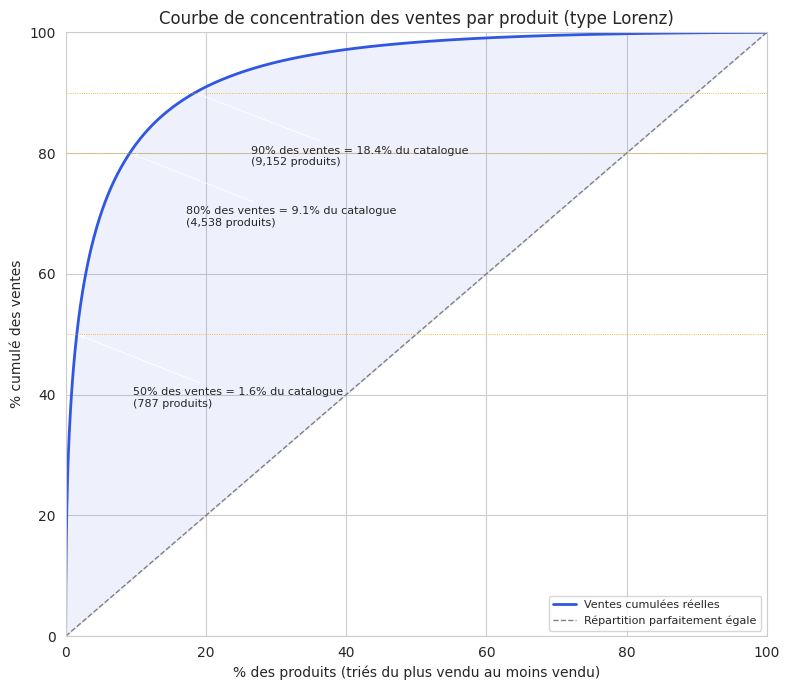

In [10]:
sales_per_product = order_products.groupby("product_id").size().sort_values(ascending=False)
total_units = sales_per_product.sum()
n_products = len(sales_per_product)

cum_products_pct = np.arange(1, n_products + 1) / n_products * 100
cum_sales_pct = sales_per_product.cumsum().values / total_units * 100

fig, ax = plt.subplots(figsize=(8, 7))
ax.plot(cum_products_pct, cum_sales_pct, color="#3057E1", linewidth=2,
        label="Ventes cumulées réelles")
ax.plot([0, 100], [0, 100], linestyle="--", color="grey", linewidth=1,
        label="Répartition parfaitement égale")
ax.fill_between(cum_products_pct, cum_sales_pct, cum_products_pct,
                 color="#3057E1", alpha=0.08)

for target in [50, 80, 90]:
    n_needed = (sales_per_product.cumsum() / total_units <= target/100).sum() + 1
    pct_catalog = 100 * n_needed / n_products
    ax.axhline(target, color="orange", linewidth=0.6, linestyle=":")
    ax.annotate(f"{target}% des ventes = {pct_catalog:.1f}% du catalogue\n({n_needed:,} produits)",
                xy=(pct_catalog, target), xytext=(pct_catalog + 8, target - 12),
                fontsize=8, arrowprops=dict(arrowstyle="->", lw=0.6))

ax.set_xlabel("% des produits (triés du plus vendu au moins vendu)")
ax.set_ylabel("% cumulé des ventes")
ax.set_title("Courbe de concentration des ventes par produit (type Lorenz)")
ax.legend(loc="lower right", fontsize=8)
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()


In [11]:
low_rotation = sales_per_product[sales_per_product <= 5]
print(f"Produits vendus au plus 5 fois sur toute la période : {len(low_rotation):,} "
      f"({100*len(low_rotation)/n_products:.1f}% du catalogue vendu)")
print(f"Leur poids dans le volume total vendu : {100*low_rotation.sum()/total_units:.3f}%")


Produits vendus au plus 5 fois sur toute la période : 3,171 (6.4% du catalogue vendu)
Leur poids dans le volume total vendu : 0.037%


**Lecture :** la concentration est extrême - **1.6 % des produits (787 réf.) génèrent 50 % des ventes**, et **9.1 % du catalogue génère 80 % des ventes**. À l'autre bout, **6.4 % des produits vendus** (3 171 références) ne représentent que **0.04 %** du volume total - une très longue traîne de produits presque jamais achetés.

**Piste d'action :** ces ~3 000 références à très faible rotation sont des candidates naturelles à un audit de déréférencement (sous réserve qu'elles ne servent pas un objectif de gamme stratégique, ex. produits de niche à forte marge ou d'image).

## Question 4 - Quels rayons sont le plus souvent achetés ensemble ?

**Objectif :** identifier des paires de rayons dont la co-présence dans une même commande dépasse ce que le hasard prédirait (indépendance des deux rayons), afin de proposer des rapprochements en magasin ou des mises en avant croisées.

**Métrique :** le **lift** - rapport entre la probabilité observée que deux rayons soient achetés ensemble et la probabilité qu'on obtiendrait s'ils étaient indépendants. `lift = 1` → indépendance, `lift > 1` → association positive.

**Graphique choisi :** heatmap (matrice) - seul format adapté pour visualiser une relation many-to-many entre catégories, distinct des barres/scatter/courbe déjà utilisés. Analyse menée aux deux niveaux demandés : département (vue d'ensemble) et rayon (plus fin).

In [12]:
def build_cooccurrence(df, col, id_range):
    """Construit la matrice de co-occurrence (nb commandes contenant à la fois cat i et cat j)
    et le lift associé, à partir d'un DataFrame contenant order_id et la colonne catégorielle."""
    pairs = df[["order_id", col]].drop_duplicates()
    order_codes, order_uniques = pd.factorize(pairs["order_id"])
    cat_codes = pairs[col].values - 1
    n_cat = len(id_range)

    mat = sparse.csr_matrix(
        (np.ones(len(pairs), dtype=np.int32), (order_codes, cat_codes)),
        shape=(len(order_uniques), n_cat)
    )
    co_matrix = (mat.T @ mat).toarray()
    support = mat.sum(axis=0).A1
    n_orders = len(order_uniques)

    lift = np.zeros_like(co_matrix, dtype=float)
    for i in range(n_cat):
        for j in range(n_cat):
            if i != j and support[i] > 0 and support[j] > 0:
                p_ij = co_matrix[i, j] / n_orders
                p_i, p_j = support[i] / n_orders, support[j] / n_orders
                lift[i, j] = p_ij / (p_i * p_j)
    return co_matrix, lift, support, n_orders

op_dept = op_full.merge(products_full[["product_id","department_id"]], on="product_id", how="left") \
    if "department_id" not in op_full.columns else op_full


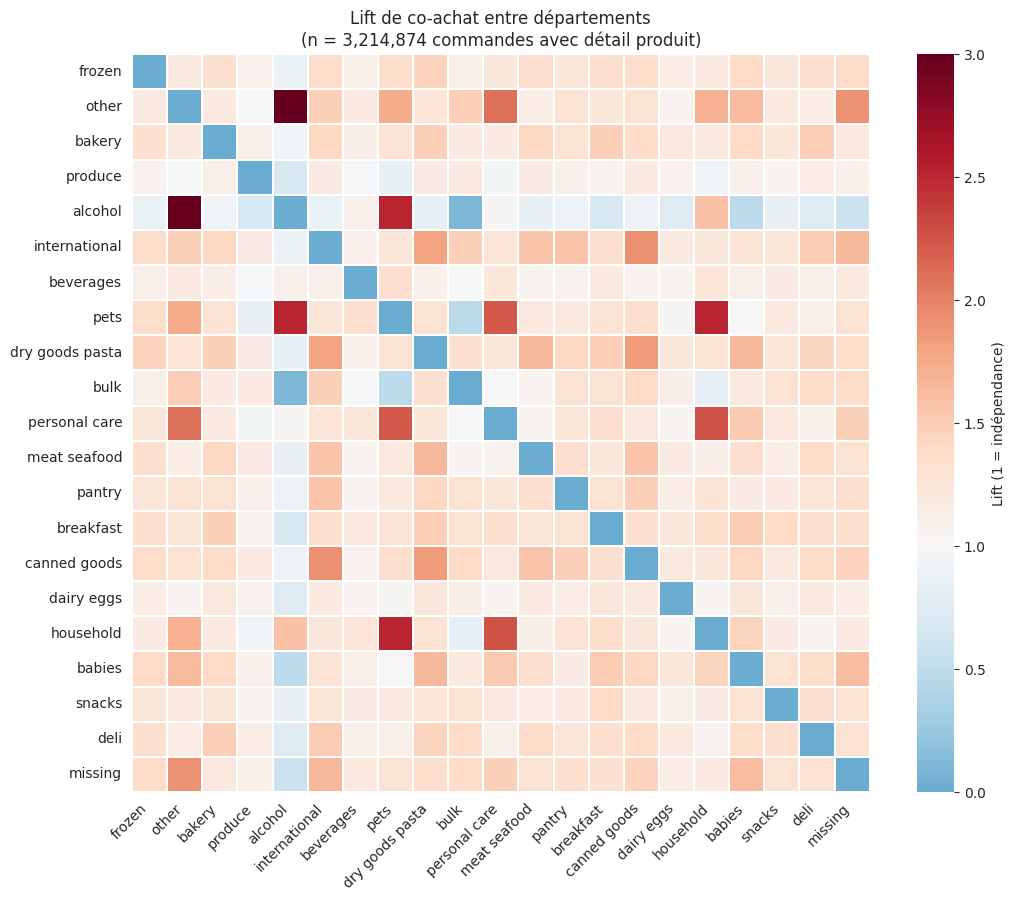

In [13]:
# --- Niveau département (21 catégories) ---
op_dept_ids = order_products.merge(products_full[["product_id","department_id"]], on="product_id")
co_dept, lift_dept, sup_dept, n_orders_detail = build_cooccurrence(
    op_dept_ids, "department_id", range(1, 22)
)
dept_names = departments.set_index("department_id")["department"].reindex(range(1, 22)).values

lift_dept_df = pd.DataFrame(lift_dept, index=dept_names, columns=dept_names)

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(lift_dept_df, cmap="RdBu_r", center=1, vmin=0, vmax=3,
            square=True, linewidths=0.3, cbar_kws={"label": "Lift (1 = indépendance)"},
            ax=ax)
ax.set_title(f"Lift de co-achat entre départements\n(n = {n_orders_detail:,} commandes avec détail produit)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


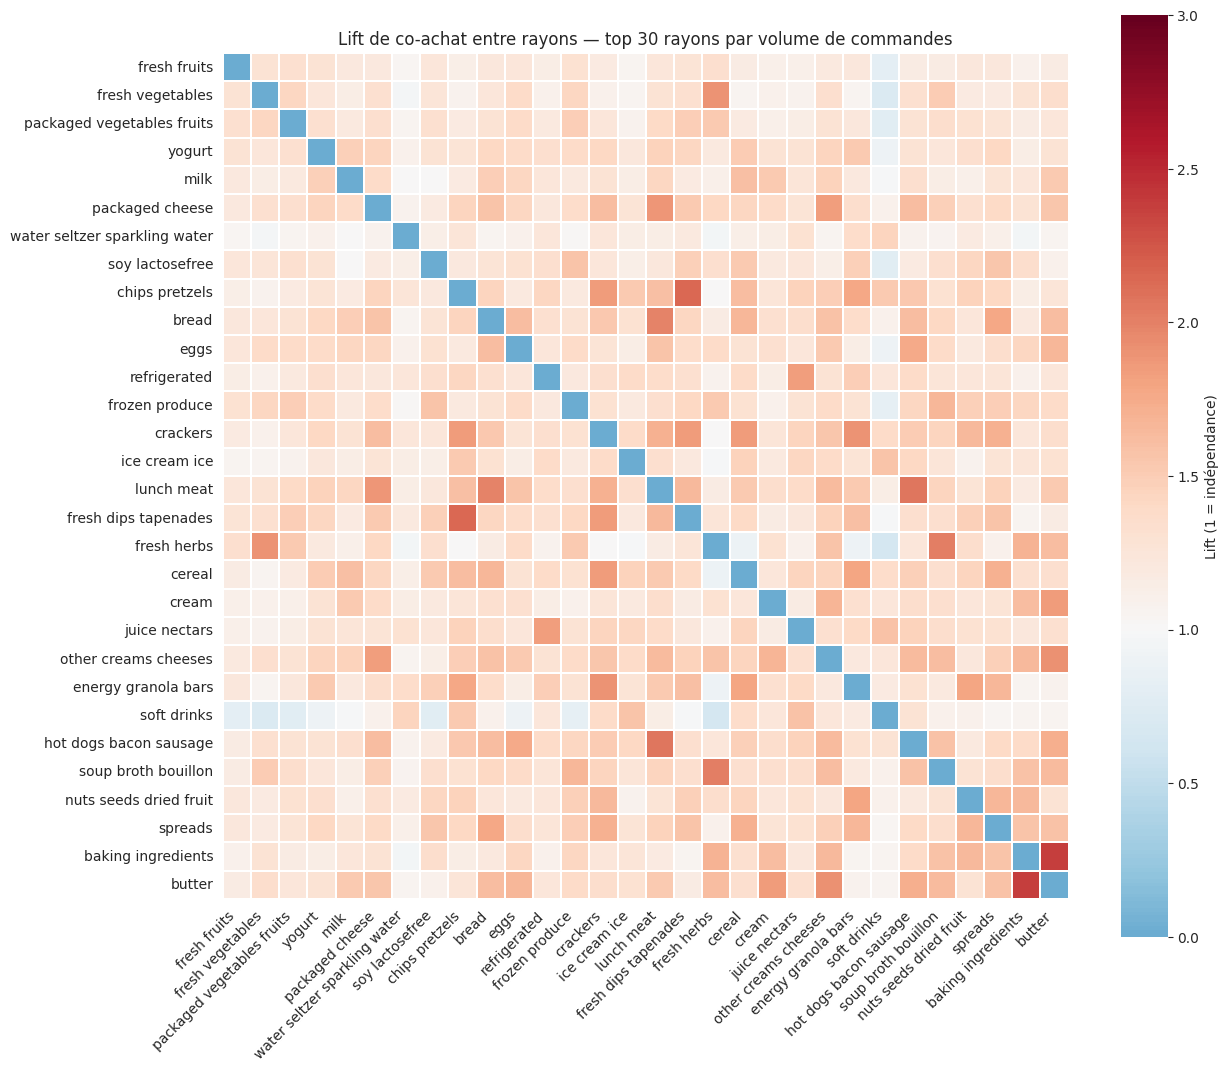

In [14]:
# --- Niveau rayon (134 catégories) - on garde les rayons ayant un minimum de volume
# pour la lisibilité de la heatmap (rayons anecdotiques exclus de l'affichage, pas du calcul)
op_aisle_ids = order_products.merge(products_full[["product_id","aisle_id"]], on="product_id")
co_aisle, lift_aisle, sup_aisle, _ = build_cooccurrence(op_aisle_ids, "aisle_id", range(1, 135))
aisle_names_all = aisles.set_index("aisle_id")["aisle"].reindex(range(1, 135)).values

# top 30 rayons par volume de commandes, pour une heatmap lisible
top30_idx = np.argsort(sup_aisle)[::-1][:30]
lift_top30 = lift_aisle[np.ix_(top30_idx, top30_idx)]
names_top30 = aisle_names_all[top30_idx]

fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(pd.DataFrame(lift_top30, index=names_top30, columns=names_top30),
            cmap="RdBu_r", center=1, vmin=0, vmax=3, square=True, linewidths=0.2,
            cbar_kws={"label": "Lift (1 = indépendance)"}, ax=ax)
ax.set_title("Lift de co-achat entre rayons - top 30 rayons par volume de commandes")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [15]:
def lift_report(name_a_substr, name_b_substr):
    ia = [i for i, n in enumerate(aisle_names_all) if name_a_substr in n][0]
    ib = [i for i, n in enumerate(aisle_names_all) if name_b_substr in n][0]
    print(f"{aisle_names_all[ia]:<25} <-> {aisle_names_all[ib]:<25} "
          f"lift={lift_aisle[ia, ib]:5.2f}   co_achats={co_aisle[ia, ib]:>7,}   "
          f"support_a={sup_aisle[ia]:>7,}   support_b={sup_aisle[ib]:>7,}")

print("Vérification des hypothèses classiques du sujet :\n")
lift_report("specialty cheeses", "red wines")
lift_report("packaged cheese", "red wines")
lift_report("other creams cheeses", "red wines")
lift_report("dog food", "cat food")


Vérification des hypothèses classiques du sujet :

specialty cheeses         <-> red wines                 lift= 1.16   co_achats=    702   support_a= 77,171   support_b= 25,306
packaged cheese           <-> red wines                 lift= 0.91   co_achats=  5,267   support_a=737,899   support_b= 25,306
other creams cheeses      <-> red wines                 lift= 1.12   co_achats=  2,456   support_a=278,180   support_b= 25,306
dog food care             <-> cat food care             lift= 4.89   co_achats=  1,371   support_a= 25,965   support_b= 34,688


**Lecture :**

- **Fromage / vin - hypothèse infirmée.** Le lift entre les rayons fromage (`specialty cheeses`, `packaged cheese`, `other creams cheeses`) et vin (`red wines`) tourne autour de **1.0-1.2**, c'est-à-dire proche de l'indépendance statistique. L'association "fromage + vin" existe dans l'imaginaire commercial, mais **n'est pas confirmée par les données** de ce dataset - attention à ne pas construire une action merchandising sur une intuition non vérifiée.
- **Chat / chien - hypothèse confirmée, et plus forte qu'attendu.** `dog food care` et `cat food care` ont un lift de **≈ 4.9** : très largement au-dessus de l'indépendance. Logique une fois qu'on y pense (foyers multi-animaux), mais l'ampleur est notable.
- **Les associations les plus fortes du dataset** concernent en réalité les **rayons alcool entre eux** (vins rouges/blancs/spéciaux, spiritueux, bières - lift jusqu'à ~39) et les **rayons soins/hygiène** (rasage/soin visage, couches/soin bébé) : des paniers "toilette" ou "cave" cohérents, plus nets que le cross-sell alimentaire classique.

**Piste d'action :** rapprocher `dog food care` et `cat food care` en rayon, envisager une mise en avant croisée alcool (vins/spiritueux/bières) plutôt que fromage/vin, et ne pas généraliser une hypothèse de merchandising sans la valider sur les données comme ici.

## Synthèse - Actions proposées (Stock / assortiment)

| # | Constat | Action proposée |
|---|---|---|
| 1 | `personal care` (6 563 réf., 20% du catalogue) ne pèse que 1.4% des ventes ; `produce` (5% du catalogue) pèse 29% des ventes | Resserrer la gamme `personal care` / `snacks` / `pantry`, réinvestir l'espace linéaire vers `produce` |
| 2 | 6.4% du catalogue vendu (~3 171 réf.) ne représente que 0.04% du volume | Auditer ces références à très faible rotation pour déréférencement, sauf exceptions stratégiques |
| 3 | Lift fromage/vin proche de 1 (hypothèse classique non confirmée) | Ne pas investir en rapprochement fromage/vin sans re-test A/B en magasin |
| 4 | Lift chat/chien ≈ 4.9, alcool entre eux jusqu'à ~39 | Rapprocher les rayons animaux, regrouper davantage l'offre alcool (vin/spiritueux/bière) |
